In [1]:
# Import Libraries
import pandas as pd
from sqlalchemy import create_engine

# Create Engine 
engine = create_engine("postgresql+psycopg2://postgres:Zxcvbnm,./123@localhost:5432/inventory")

# Import .csv
df = pd.read_csv(r"C:\Users\HP\Desktop\inventory.csv")

print(type(df))
print(df.shape)
print(df.head())

<class 'pandas.DataFrame'>
(1501, 5)
   item_id store_id        date  sales_qty  stock_on_hand
0  ITEM025  STORE07  10/04/2025       54.0           77.0
1  ITEM158  STORE06  01/10/2025       60.0         1194.0
2  ITEM022  STORE06  10/18/2025       12.0          184.0
3  ITEM067  STORE01  04/09/2025        9.0          316.0
4  ITEM097  STORE01   4/26/2025       11.0          457.0


In [2]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after deleting duplicates:", df.shape)

Duplicate rows: 3
Shape after deleting duplicates: (1498, 5)


In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date column type:", df["date"].dtype)
print("Invalid dates:", df["date"].isna().sum())
print(df["date"].head())

Date column type: datetime64[us]
Invalid dates: 1
0   2025-10-04
1   2025-01-10
2   2025-10-18
3   2025-04-09
4   2025-04-26
Name: date, dtype: datetime64[us]


In [7]:
# Fill missing sales_qty with 0 (assuming no sales that day)
df['sales_qty'] = df['sales_qty'].fillna(0)

# Fill missing stock_on_hand with median (better than mean for inventory)
df['stock_on_hand'] = df['stock_on_hand'].fillna(df['stock_on_hand'].median())

print(df.isnull().sum())

item_id          0
store_id         0
date             1
sales_qty        0
stock_on_hand    0
dtype: int64


In [6]:
print(df.isnull().sum())

item_id          0
store_id         0
date             1
sales_qty        0
stock_on_hand    0
dtype: int64


In [8]:
df = df.dropna(subset=['date'])
print("Shape after removing invalid date:", df.shape)
print(df.isnull().sum())

Shape after removing invalid date: (1497, 5)
item_id          0
store_id         0
date             0
sales_qty        0
stock_on_hand    0
dtype: int64


In [9]:
print("Negative sales_qty:", (df['sales_qty'] < 0).sum())
print("Negative stock_on_hand:", (df['stock_on_hand'] < 0).sum())

# Optional: convert negatives to 0 (or remove them)
df['sales_qty'] = df['sales_qty'].clip(lower=0)
df['stock_on_hand'] = df['stock_on_hand'].clip(lower=0)

print("After fixing negatives:")
print("Negative sales_qty:", (df['sales_qty'] < 0).sum())
print("Negative stock_on_hand:", (df['stock_on_hand'] < 0).sum())

Negative sales_qty: 49
Negative stock_on_hand: 35
After fixing negatives:
Negative sales_qty: 0
Negative stock_on_hand: 0


In [10]:
# Stock Status
df['stock_status'] = df['stock_on_hand'].apply(
    lambda x: 'Stockout' if x == 0 else ('Low Stock' if x < 50 else 'Healthy')
)

# High Demand Flag
df['high_demand'] = (df['sales_qty'] > df['sales_qty'].median()).astype(int)

print(df['stock_status'].value_counts())
print(df.head())

stock_status
Healthy      1335
Low Stock     126
Stockout       36
Name: count, dtype: int64
   item_id store_id       date  sales_qty  stock_on_hand stock_status  \
0  ITEM025  STORE07 2025-10-04       54.0           77.0      Healthy   
1  ITEM158  STORE06 2025-01-10       60.0         1194.0      Healthy   
2  ITEM022  STORE06 2025-10-18       12.0          184.0      Healthy   
3  ITEM067  STORE01 2025-04-09        9.0          316.0      Healthy   
4  ITEM097  STORE01 2025-04-26       11.0          457.0      Healthy   

   high_demand  
0            1  
1            1  
2            0  
3            0  
4            0  


In [11]:
print("Total records:", len(df))
print("Average stock on hand:", round(df['stock_on_hand'].mean(), 2))
print("Average sales qty:", round(df['sales_qty'].mean(), 2))
print("\nStock Status Breakdown:")
print(df['stock_status'].value_counts(normalize=True).mul(100).round(2))

Total records: 1497
Average stock on hand: 327.84
Average sales qty: 44.59

Stock Status Breakdown:
stock_status
Healthy      89.18
Low Stock     8.42
Stockout      2.40
Name: proportion, dtype: float64


In [12]:
# Total stockouts
print("Total Stockout records:", (df['stock_status'] == 'Stockout').sum())

# Stockouts by Store
stockout_by_store = df[df['stock_status'] == 'Stockout'].groupby('store_id').size().sort_values(ascending=False)
print("\nStockouts by Store:")
print(stockout_by_store)

# Stockouts by Item (Top 10)
stockout_by_item = df[df['stock_status'] == 'Stockout'].groupby('item_id').size().sort_values(ascending=False).head(10)
print("\nTop Items with Stockouts:")
print(stockout_by_item)


Total Stockout records: 36

Stockouts by Store:
store_id
STORE01    7
STORE03    6
STORE02    5
STORE06    5
STORE09    3
STORE07    3
STORE10    3
STORE08    2
STORE05    1
STORE04    1
dtype: int64

Top Items with Stockouts:
item_id
ITEM050    2
ITEM189    2
ITEM127    2
ITEM004    1
ITEM013    1
ITEM030    1
ITEM031    1
ITEM028    1
ITEM025    1
ITEM060    1
dtype: int64


In [13]:
# Top 10 highest selling items
top_items = df.groupby('item_id')['sales_qty'].sum().sort_values(ascending=False).head(10)
print("Top 10 Highest Selling Items:")
print(top_items)

# Sales by Store
sales_by_store = df.groupby('store_id')['sales_qty'].sum().sort_values(ascending=False)
print("\nTotal Sales by Store:")
print(sales_by_store)

# Average sales per store
avg_sales_store = df.groupby('store_id')['sales_qty'].mean().sort_values(ascending=False).round(2)
print("\nAverage Sales Qty by Store:")
print(avg_sales_store)

Top 10 Highest Selling Items:
item_id
ITEM161    1138.0
ITEM198    1000.0
ITEM182     975.0
ITEM187     911.0
ITEM089     875.0
ITEM083     808.0
ITEM028     781.0
ITEM108     765.0
ITEM163     747.0
ITEM100     692.0
Name: sales_qty, dtype: float64

Total Sales by Store:
store_id
STORE03    8561.0
STORE01    7997.0
STORE08    7113.0
STORE02    6814.0
STORE04    6779.0
STORE06    6608.0
STORE10    6127.0
STORE05    5950.0
STORE09    5607.0
STORE07    5198.0
Name: sales_qty, dtype: float64

Average Sales Qty by Store:
store_id
STORE03    53.17
STORE01    49.67
STORE06    48.95
STORE02    47.32
STORE08    44.46
STORE04    41.59
STORE10    40.58
STORE09    40.34
STORE07    39.68
STORE05    39.14
Name: sales_qty, dtype: float64


In [14]:
# Create a simple efficiency view
efficiency = df.groupby('item_id').agg({
    'sales_qty': 'sum',
    'stock_on_hand': 'mean'
}).round(2)

efficiency.columns = ['Total_Sales', 'Avg_Stock']

# Flag potential issues
efficiency['Overstock_Risk'] = (efficiency['Avg_Stock'] > efficiency['Avg_Stock'].quantile(0.75)) & \
                               (efficiency['Total_Sales'] < efficiency['Total_Sales'].median())

efficiency['Stockout_Risk'] = (efficiency['Avg_Stock'] < efficiency['Avg_Stock'].quantile(0.25)) & \
                              (efficiency['Total_Sales'] > efficiency['Total_Sales'].median())

print("Potential Overstock Items (High stock + Low sales):")
print(efficiency[efficiency['Overstock_Risk']].sort_values('Avg_Stock', ascending=False).head(10))

print("\nPotential Stockout Risk Items (Low stock + High sales):")
print(efficiency[efficiency['Stockout_Risk']].sort_values('Total_Sales', ascending=False).head(10))

Potential Overstock Items (High stock + Low sales):
         Total_Sales  Avg_Stock  Overstock_Risk  Stockout_Risk
item_id                                                       
ITEM055        300.0    1392.56            True          False
ITEM025        259.0    1384.33            True          False
ITEM200        169.0    1350.50            True          False
ITEM094        281.0     930.00            True          False
ITEM041        156.0     790.83            True          False
ITEM040        255.0     736.12            True          False
ITEM096        246.0     724.00            True          False
ITEM179        272.0     688.00            True          False
ITEM003        243.0     684.00            True          False
ITEM064        269.0     668.00            True          False

Potential Stockout Risk Items (Low stock + High sales):
         Total_Sales  Avg_Stock  Overstock_Risk  Stockout_Risk
item_id                                                       
ITEM198  

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (16, 12)

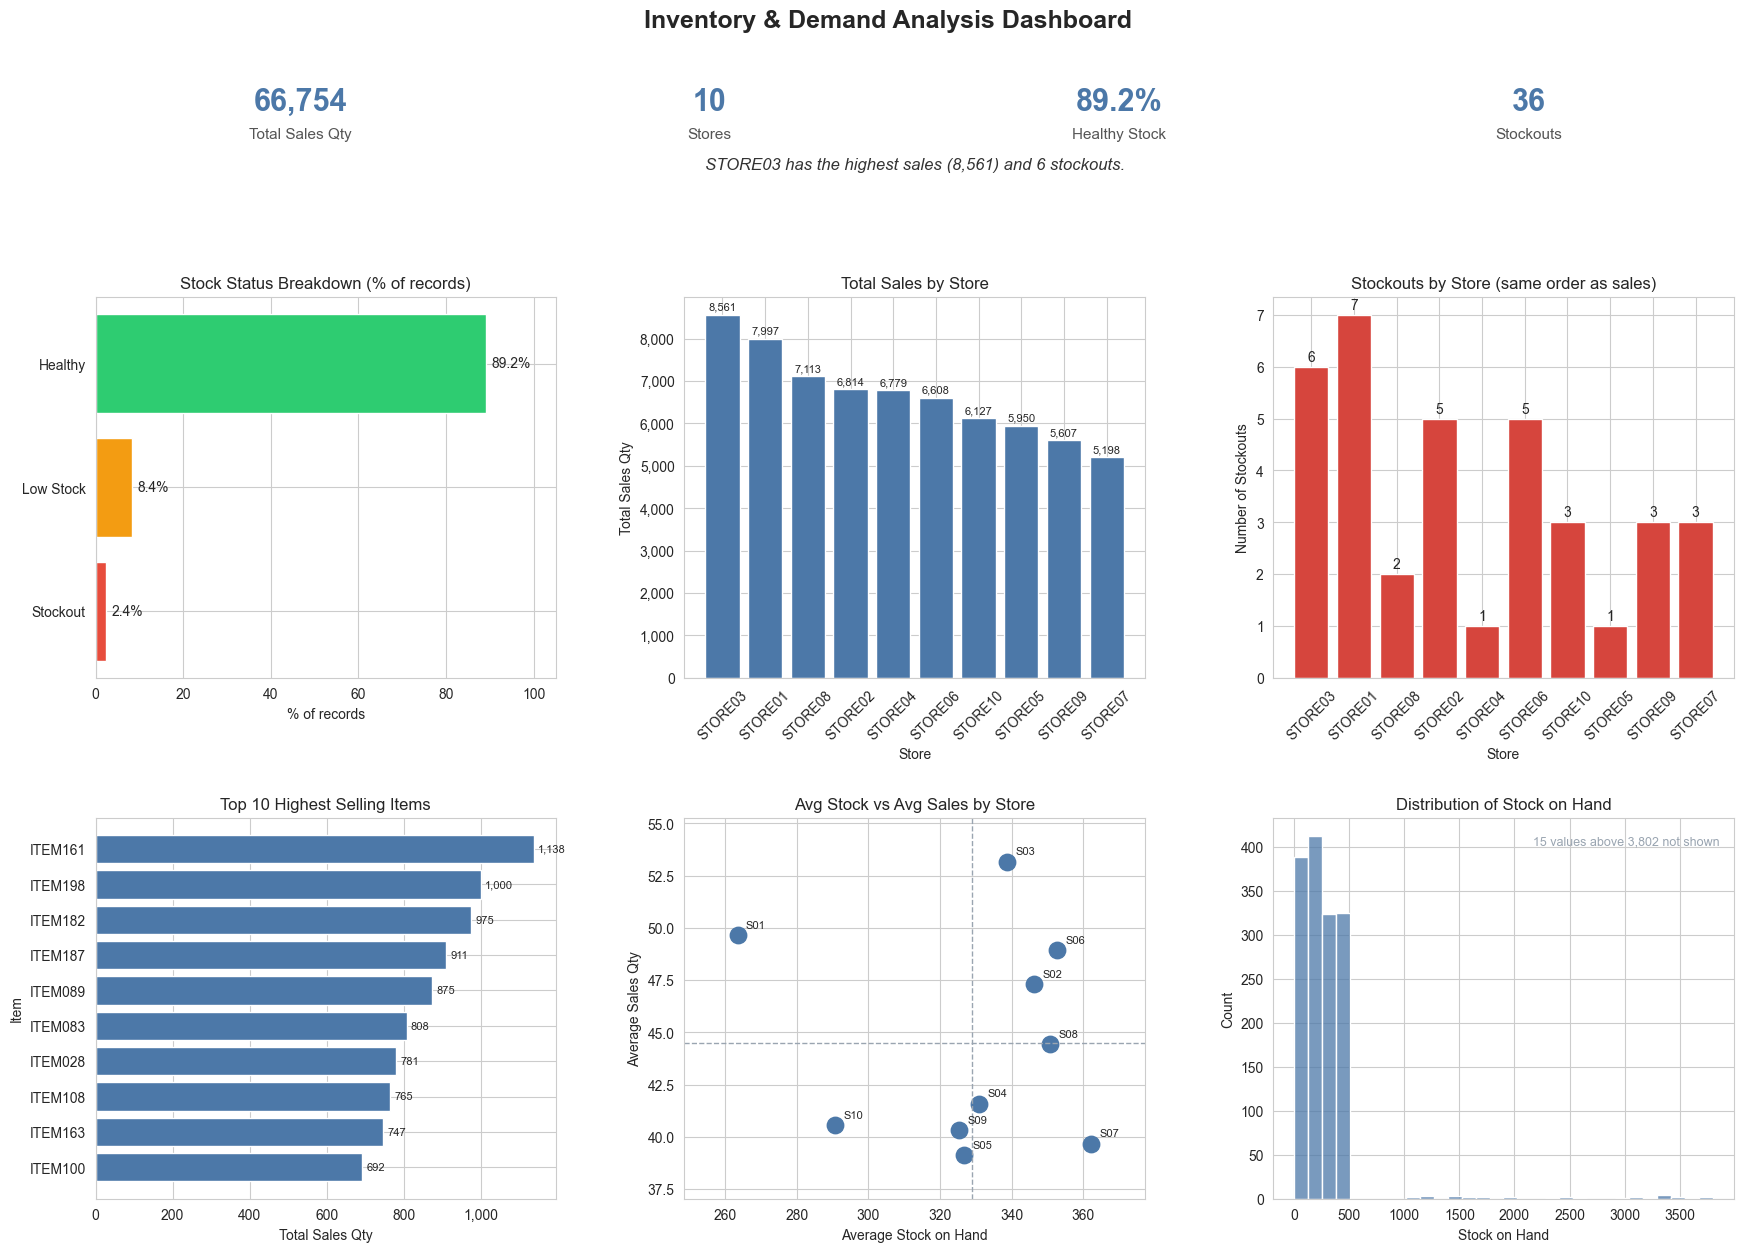

Dashboard saved as inventory_dashboard.png


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Assumes `df` is already loaded with: store_id, item_id, sales_qty,
# stock_on_hand, stock_status (Healthy / Low Stock / Stockout)

sns.set_style('whitegrid')
BLUE, RED, GREY = '#4C78A8', '#D6453D', '#9AA5B1'
STATUS_COLORS = {'Healthy': '#2ecc71', 'Low Stock': '#f39c12', 'Stockout': '#e74c3c'}
thousands = FuncFormatter(lambda x, _: f'{x:,.0f}')

# ---------- Prepare data ----------
sales_by_store = df.groupby('store_id')['sales_qty'].sum().sort_values(ascending=False)
store_order = sales_by_store.index.tolist()          # one order for both store charts
stockouts = (df[df['stock_status'] == 'Stockout']
             .groupby('store_id').size()
             .reindex(store_order, fill_value=0))
status_pct = (df['stock_status'].value_counts(normalize=True) * 100) \
    .reindex(['Healthy', 'Low Stock', 'Stockout']).fillna(0)
top_items = df.groupby('item_id')['sales_qty'].sum().sort_values(ascending=False).head(10)
store_summary = df.groupby('store_id').agg(sales_qty=('sales_qty', 'mean'),
                                           stock_on_hand=('stock_on_hand', 'mean'))
cap = df['stock_on_hand'].quantile(0.99)
n_outliers = int((df['stock_on_hand'] > cap).sum())

# ---------- Layout: KPI strip + 2x3 charts ----------
fig = plt.figure(figsize=(18, 13))
gs = GridSpec(3, 3, figure=fig, height_ratios=[0.2, 1, 1], hspace=0.5, wspace=0.28,
              top=0.93, bottom=0.07, left=0.06, right=0.97)
fig.suptitle('Inventory & Demand Analysis Dashboard', fontsize=18, fontweight='bold', y=0.985)

# KPI strip
ax_k = fig.add_subplot(gs[0, :])
ax_k.axis('off')
kpis = [('Total Sales Qty', f'{df["sales_qty"].sum():,.0f}'),
        ('Stores', f'{df["store_id"].nunique()}'),
        ('Healthy Stock', f'{status_pct["Healthy"]:.1f}%'),
        ('Stockouts', f'{int(stockouts.sum())}')]
for i, (label, value) in enumerate(kpis):
    x = 0.125 + i * 0.25
    ax_k.text(x, 0.72, value, ha='center', va='center', fontsize=22, fontweight='bold', color=BLUE)
    ax_k.text(x, 0.30, label, ha='center', va='center', fontsize=11, color='#555')
top_store = store_order[0]
ax_k.text(0.5, -0.1,
          f'{top_store} has the highest sales ({sales_by_store[top_store]:,.0f}) '
          f'and {stockouts[top_store]} stockouts.',
          ha='center', va='center', fontsize=12, style='italic', color='#333')

# 1. Stock status (bar instead of pie)
ax = fig.add_subplot(gs[1, 0])
bars = ax.barh(status_pct.index, status_pct.values,
               color=[STATUS_COLORS[s] for s in status_pct.index])
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in status_pct.values], padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_title('Stock Status Breakdown (% of records)')
ax.set_xlabel('% of records')

# 2. Sales by store
ax = fig.add_subplot(gs[1, 1])
bars = ax.bar(store_order, sales_by_store.values, color=BLUE)
ax.bar_label(bars, labels=[f'{v:,.0f}' for v in sales_by_store.values], fontsize=8, padding=2)
ax.set_title('Total Sales by Store')
ax.set_xlabel('Store')
ax.set_ylabel('Total Sales Qty')
ax.yaxis.set_major_formatter(thousands)
ax.tick_params(axis='x', rotation=45)

# 3. Stockouts by store (same order as sales)
ax = fig.add_subplot(gs[1, 2])
bars = ax.bar(store_order, stockouts.values, color=RED)
ax.bar_label(bars, labels=[str(v) if v else '' for v in stockouts.values], padding=2)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title('Stockouts by Store (same order as sales)')
ax.set_xlabel('Store')
ax.set_ylabel('Number of Stockouts')
ax.tick_params(axis='x', rotation=45)

# 4. Top 10 items
ax = fig.add_subplot(gs[2, 0])
bars = ax.barh(top_items.index, top_items.values, color=BLUE)
ax.bar_label(bars, labels=[f'{v:,.0f}' for v in top_items.values], padding=3, fontsize=8)
ax.invert_yaxis()
ax.set_title('Top 10 Highest Selling Items')
ax.set_xlabel('Total Sales Qty')
ax.set_ylabel('Item')
ax.xaxis.set_major_formatter(thousands)

# 5. Avg stock vs avg sales, labelled, with dashed average lines
ax = fig.add_subplot(gs[2, 1])
ax.scatter(store_summary['stock_on_hand'], store_summary['sales_qty'], s=140, color=BLUE)
for store, row in store_summary.iterrows():
    ax.annotate(store.replace('STORE', 'S'), (row['stock_on_hand'], row['sales_qty']),
                xytext=(6, 5), textcoords='offset points', fontsize=8)
ax.axvline(store_summary['stock_on_hand'].mean(), color=GREY, ls='--', lw=1)
ax.axhline(store_summary['sales_qty'].mean(), color=GREY, ls='--', lw=1)
ax.margins(0.15)
ax.set_title('Avg Stock vs Avg Sales by Store')
ax.set_xlabel('Average Stock on Hand')
ax.set_ylabel('Average Sales Qty')

# 6. Stock on hand distribution, clipped at the 99th percentile
ax = fig.add_subplot(gs[2, 2])
sns.histplot(df.loc[df['stock_on_hand'] <= cap, 'stock_on_hand'], bins=30,
             kde=False, color=BLUE, ax=ax)
ax.set_title('Distribution of Stock on Hand')
ax.set_xlabel('Stock on Hand')
ax.set_ylabel('Count')
ax.text(0.97, 0.95, f'{n_outliers} values above {cap:,.0f} not shown',
        transform=ax.transAxes, ha='right', va='top', fontsize=9, color=GREY)

plt.savefig('inventory_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Dashboard saved as inventory_dashboard.png')

## Insights

1. Overall inventory health is good. 89.2% of records show healthy stock levels, 8.4% show low stock and only 2.4% are stockouts.
2. Stockouts are few and concentrated. There were only 36 stockout records, and STORE01 and STORE03 had the most.
3. STORE03 and STORE01 are the top performing stores. They lead in both total sales and average sales quantity.
4. ITEM161, ITEM198 and ITEM182 are the top-selling products, so they need closer inventory monitoring.
5. Some items may be overstocked. ITEM055, ITEM025 and ITEM200, among others, have very high average stock but relatively low sales, which ties up capital.
6. Fast movers are at risk of running out. ITEM198, ITEM182 and ITEM089 have comparatively low average stock for how much they sell, which raises the chance of future stockouts.

## Recommendations

1. Cut stock of overstocked, low-sales items to free up capital.
2. Raise safety stock for high-demand items that currently have low inventory.
3. Pay extra attention to STORE01 and STORE03, which have both the highest sales and the most stockouts.
4. Set clearer reorder points based on sales velocity.
5. Review slow-moving, high-stock items for promotions or smaller orders.